# Representation Learning
- Unsupervised machine learning model to perform a clustering task on images of handwritten digits (MNIST dataset), using principal component analysis (PCA) and the t-SNE algorithm. The eigenvectors (components) of the input data’s covariance matrix are calculated and the digits are plotted against the two largest eigenvectors.

## Principal Component Analysis (PCA) - MNIST dataset

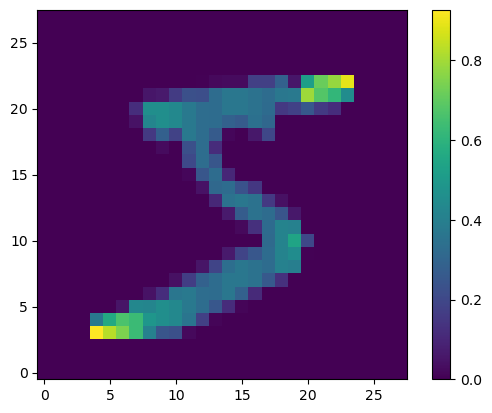

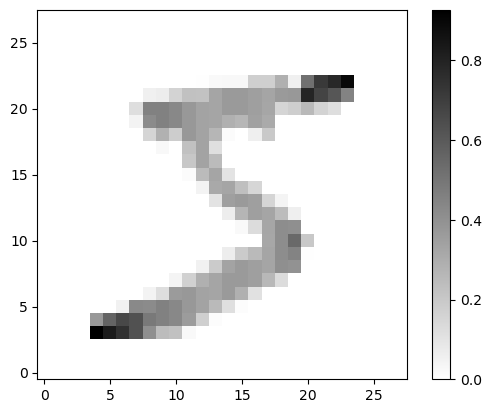

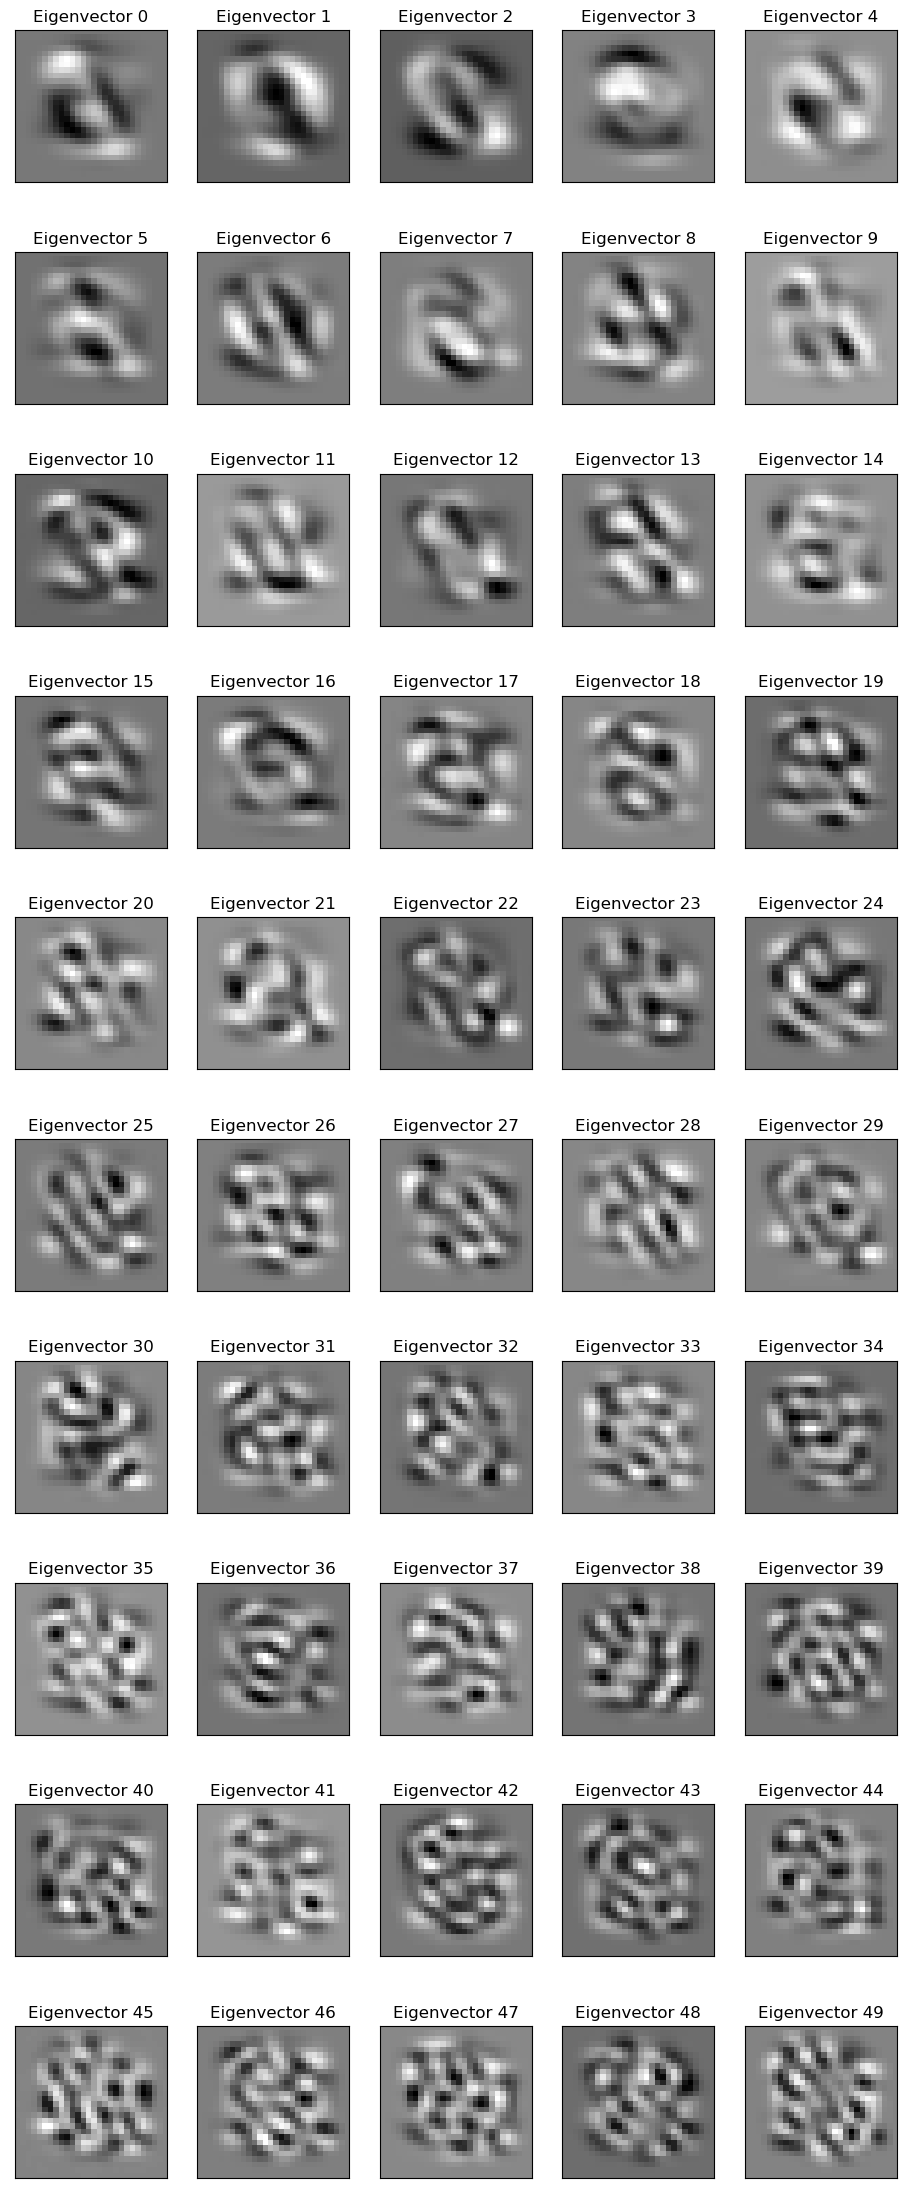

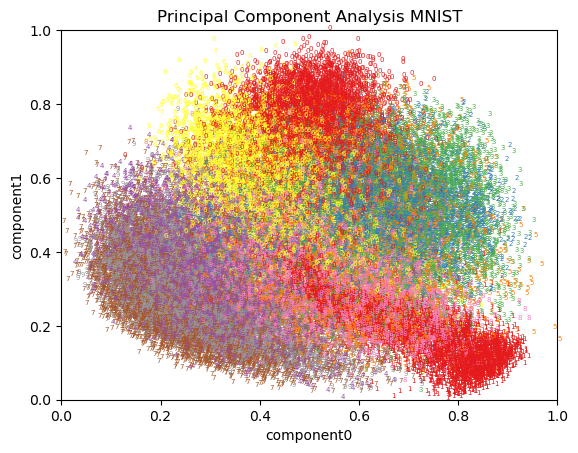

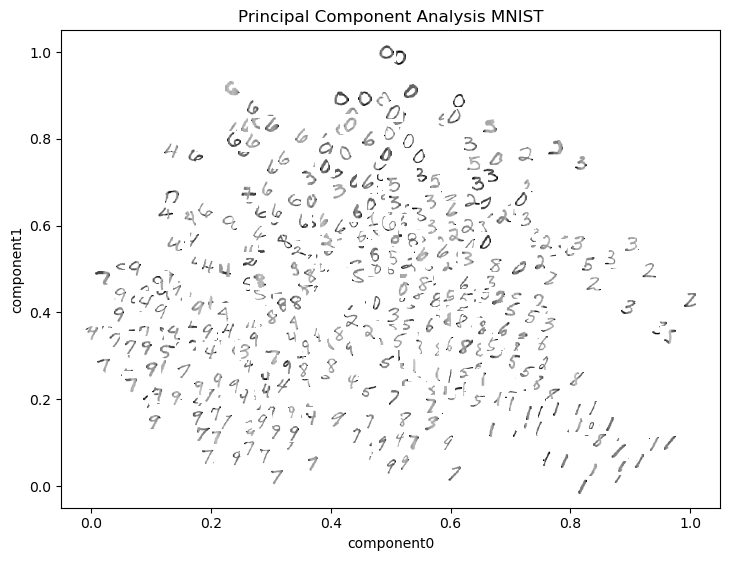

In [8]:
"""
Edited by Apoorva Upadhyay

Principal component analysis.
t-SNE
Clustering

Thanks to scikit-learn documentation 
"""

# 4.2 PCA with MNIST


from tensorflow.keras.datasets import mnist
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# flip digit images and so we can plot normally
for i in range(len(x_train)):
    x_train[i] = cv2.flip(x_train[i], 0)
    
for i in range(len(x_test)):
    x_test[i] = cv2.flip(x_test[i], 0)

plt.imshow(x_train[0],interpolation='nearest',origin='lower')
plt.axis()
plt.colorbar()
plt.show()

plt.imshow(x_train[0],interpolation='nearest',origin='lower', cmap=plt.cm.binary)
plt.axis()
plt.colorbar()
plt.show()

def CreateImgRowVec(Imgarray):
    
    imgRowVec = np.reshape(Imgarray,(1,np.size(Imgarray)))
    
    return imgRowVec

NoOfImages, h, w = np.shape(x_train)
    
AllImagesData = np.zeros((NoOfImages, h*w))

for i in range(NoOfImages):
    
    AllImagesData[i,:] = CreateImgRowVec(x_train[i])
    
####################################
    
def plot_gallery(images, h, w, PlotSave, n_row=10, n_col=5): # images, titles, h, w, n_row=10, n_col=5
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    #plt.title('Eigenvectors')
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i,:].reshape((h, w)), cmap=plt.cm.gray)
        #plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

        plt.title('Eigenvector {}'.format(i))

        plt.savefig(str(PlotSave)+'.pdf', bbox_inches = 'tight', dpi=250)

####################################  
    
from sklearn.decomposition import PCA

pca = PCA(n_components=50)

pca.fit(AllImagesData)
    
####################################
# plot 50 eigenvectors

plot_gallery(pca.components_, h, w, 'eigenvectors')

####################################
# 2 dim embeddings

pca.n_components = 2

data_2 = pca.fit_transform(AllImagesData)

####################################
# plot embeddings func

def plot_embedding(data_dim, labels, title=None):
    
    x_min, x_max = np.min(data_dim,0), np.max(data_dim,0)
    
    data_dim = (data_dim - x_min) / (x_max - x_min)
        
    plt.figure()
    
    
    for i in range(data_dim.shape[0]): # i runs over no of images images
        plt.text(data_dim[i,0], data_dim[i,1], str(labels[i]), color=plt.cm.Set1(labels[i]/10.), fontsize = 5)
        
        
    if title is not None:
        plt.title(title)
        
    plt.xlabel('component0')    
    plt.ylabel('component1')

        
    plt.savefig(title+'.pdf', bbox_inches = 'tight', dpi=250)

        
    plt.show()
    
    
####################################
# plot 2d embedding PCA MNIST

plot_embedding(data_2, y_train, 'Principal Component Analysis MNIST')

####################################
# plot mnist images as scatter points

# 100 random images

y_train = y_train.reshape(60000,1)

random_100 = np.concatenate((data_2,y_train), axis=1)

NumberOfMnistImgs = 500

indices = np.random.choice(random_100.shape[0], NumberOfMnistImgs, replace=False)

# arrays to be passed into plot_embedding_ImgScatter func
random_100_true = random_100[indices]
AllImagesData_random_100 = AllImagesData[indices]


# define plot func

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def plot_embedding_ImgScatter(data_dim, AllRandomImages, title=None): # data_dim, labels, AllRandomImages, title=None
    
    x_min, x_max = np.min(data_dim,0), np.max(data_dim,0)
    
    data_dim = (data_dim - x_min) / (x_max - x_min)
        
    
    fig, ax = plt.subplots(1, 1, figsize=[8.5, 6.2])
    #fig, ax = plt.figure()
    
    
    for i in range(data_dim.shape[0]): # i runs over no of images images
        #plt.text(data_dim[i,0], data_dim[i,1], str(labels[i]), color=plt.cm.Set1(labels[i]/10.), fontsize = 5)
        image = AllRandomImages[i,:].reshape((h, w))
        image = cv2.flip(image, 0)
        im = OffsetImage(image, zoom=0.5, cmap=plt.cm.binary)
        ab = AnnotationBbox(im, (data_dim[i,0], data_dim[i,1]), xycoords='data', frameon=False)
        ax.add_artist(ab)
        ax.update_datalim([(data_dim[i,0], data_dim[i,1])])
        ax.autoscale()
        
    if title is not None:
        plt.title(title)
        
    plt.xlabel('component0') # eigenvector 0   
    plt.ylabel('component1') # eigenvector 1

        
    plt.savefig(title+'.pdf', bbox_inches = 'tight', dpi=250)

        
    plt.show()
    
####################################
plot_embedding_ImgScatter(random_100_true, AllImagesData_random_100, 'Principal Component Analysis MNIST')

####################################


## t-SNE algorithm - MNIST dataset

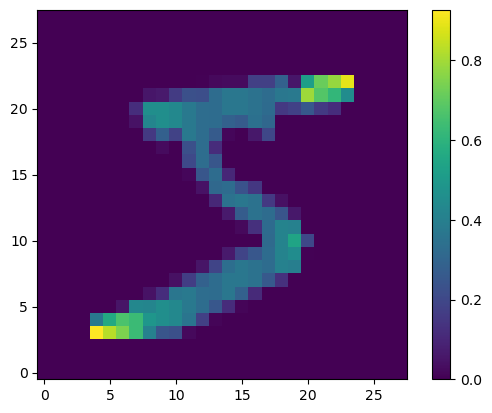

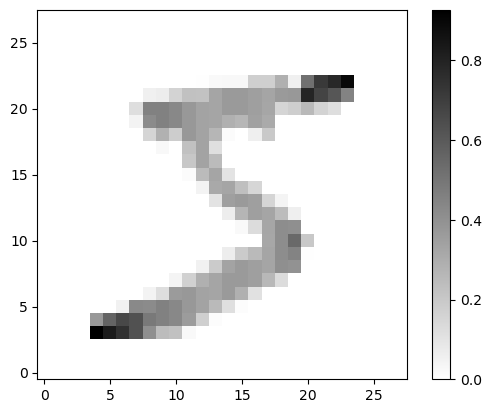

/opt/anaconda3/envs/test_machine_learning_2_py3_7/lib/python3.7/site-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,
/opt/anaconda3/envs/test_machine_learning_2_py3_7/lib/python3.7/site-packages/sklearn/manifold/_t_sne.py:986: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  FutureWarning,


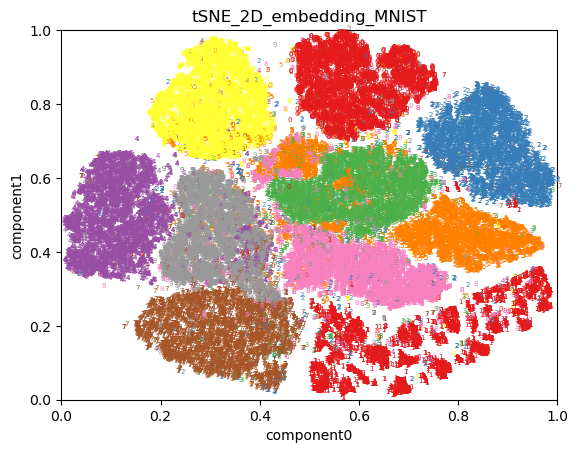

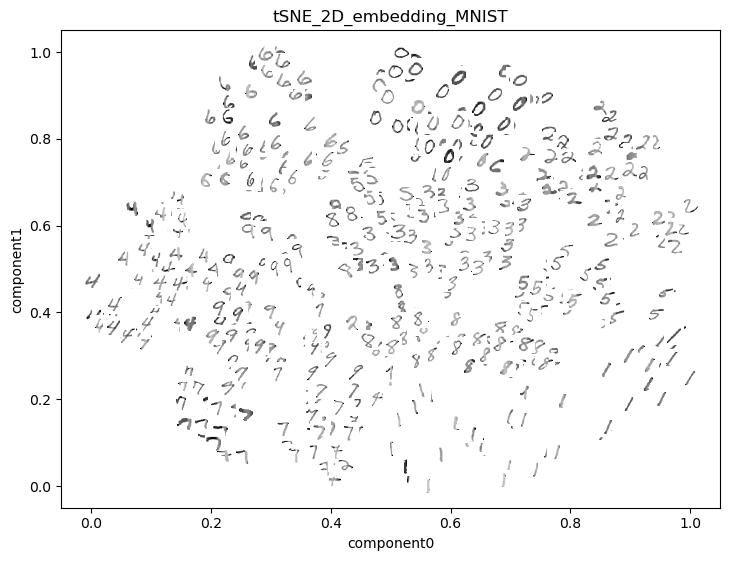

In [3]:
# 4.3 t-SNE on MNIST

from tensorflow.keras.datasets import mnist
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np

(x_train_save, y_train_save), (x_test_save, y_test_save) = mnist.load_data()

##########################
# save mnist data locally

#np.savez('x_train_mnist.npz', *x_train_save)
#np.savez('y_train_mnist.npz', *y_train_save)
#np.savez('x_test_mnist.npz', *x_test_save)
#np.savez('y_test_mnist.npz', *y_test_save)


container1 = np.load('x_train_mnist.npz')
x_train = [container1[key] for key in container1]

container2 = np.load('y_train_mnist.npz')
y_train = [container2[key] for key in container2]

container3 = np.load('x_test_mnist.npz')
x_test = [container3[key] for key in container3]

container4 = np.load('y_test_mnist.npz')
y_test = [container4[key] for key in container4]



y_train = (np.array(y_train)).reshape(60000,)
y_test = (np.array(y_test)).reshape(10000,)


#########################

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# flip digit images and so we can plot normally
for i in range(len(x_train)):
    x_train[i] = cv2.flip(x_train[i], 0)
    
for i in range(len(x_test)):
    x_test[i] = cv2.flip(x_test[i], 0)

plt.imshow(x_train[0],interpolation='nearest',origin='lower')
plt.axis()
plt.colorbar()
plt.show()

plt.imshow(x_train[0],interpolation='nearest',origin='lower', cmap=plt.cm.binary)
plt.axis()
plt.colorbar()
plt.show()

def CreateImgRowVec(Imgarray):
    
    imgRowVec = np.reshape(Imgarray,(1,np.size(Imgarray)))
    
    return imgRowVec

NoOfImages, h, w = np.shape(x_train)
    
AllImagesData = np.zeros((NoOfImages, h*w))

for i in range(NoOfImages):
    
    AllImagesData[i,:] = CreateImgRowVec(x_train[i])
    
####################################
    
def plot_gallery(images, h, w, PlotSave, n_row=10, n_col=5): # images, titles, h, w, n_row=10, n_col=5
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i,:].reshape((h, w)), cmap=plt.cm.gray)
        #plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
        
        #plt.savefig(str(PlotSave)+'.pdf', bbox_inches = 'tight', dpi=250)

####################################

from sklearn import manifold

tsne = manifold.TSNE(n_components=2, init='pca', random_state=0)

# 2 dim tsne embedding
data_2_tsne = tsne.fit_transform(AllImagesData)

####################################
# plot embeddings func

def plot_embedding(data_dim, labels, title=None):
    
    x_min, x_max = np.min(data_dim,0), np.max(data_dim,0)
    
    data_dim = (data_dim - x_min) / (x_max - x_min)
        
    plt.figure()
    
    
    for i in range(data_dim.shape[0]): # i runs over no of images images
        plt.text(data_dim[i,0], data_dim[i,1], str(labels[i]), color=plt.cm.Set1(labels[i]/10.), fontsize = 5)
        
        
    if title is not None:
        plt.title(title)
        
    plt.xlabel('component0')    
    plt.ylabel('component1')

        
    #plt.savefig(title+'.pdf', bbox_inches = 'tight', dpi=250)

        
    plt.show()
    
    
####################################
# plot 2d embedding tSNE MNIST

plot_embedding(data_2_tsne, y_train, 'tSNE_2D_embedding_MNIST')

####################################
def plot_gallery_tsne(images, h, w, PlotSave, n_row=1, n_col=2): # images, titles, h, w, n_row=10, n_col=5
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i,:].reshape((h, w)), cmap=plt.cm.gray)
        #plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
        
        #plt.savefig(str(PlotSave)+'.pdf', bbox_inches = 'tight', dpi=250)

####################################  
    
# plot 2 tSNE eigenvectors

#plot_gallery_tsne(tsne.embedding_, h, w, 'MNIST_tSNE_2D_eigenvectors')

# TSNE NOT PRINTING OUT EIGENVECTORS?
####################################


####################################
# plot mnist images as scatter points

# 100 random images

y_train = y_train.reshape(60000,1)

random_100 = np.concatenate((data_2_tsne,y_train), axis=1)

NumberOfMnistImgs = 500

indices = np.random.choice(random_100.shape[0], NumberOfMnistImgs, replace=False)

# arrays to be passed into plot_embedding_ImgScatter func
random_100_true = random_100[indices]
AllImagesData_random_100 = AllImagesData[indices]


# define plot func

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def plot_embedding_ImgScatter(data_dim, AllRandomImages, title=None): # data_dim, labels, AllRandomImages, title=None
    
    x_min, x_max = np.min(data_dim,0), np.max(data_dim,0)
    
    data_dim = (data_dim - x_min) / (x_max - x_min)
        
    
    fig, ax = plt.subplots(1, 1, figsize=[8.5, 6.2])
    #fig, ax = plt.figure()
    
    
    for i in range(data_dim.shape[0]): # i runs over no of images images
        #plt.text(data_dim[i,0], data_dim[i,1], str(labels[i]), color=plt.cm.Set1(labels[i]/10.), fontsize = 5)
        image = AllRandomImages[i,:].reshape((h, w))
        image = cv2.flip(image, 0)
        #im = OffsetImage(image, zoom=0.5)
        im = OffsetImage(image, zoom=0.5, cmap=plt.cm.binary) # cmap=plt.cm.binary for no purple background
        ab = AnnotationBbox(im, (data_dim[i,0], data_dim[i,1]), xycoords='data', frameon=False)
        ax.add_artist(ab)
        ax.update_datalim([(data_dim[i,0], data_dim[i,1])])
        ax.autoscale()
        
    if title is not None:
        plt.title(title)
        
    plt.xlabel('component0') # eigenvector 0   
    plt.ylabel('component1') # eigenvector 1

        
    #plt.savefig(title+'.pdf', bbox_inches = 'tight', dpi=250)

        
    plt.show()
    
####################################
plot_embedding_ImgScatter(random_100_true, AllImagesData_random_100, 'tSNE_2D_embedding_MNIST')


## Conclusion
- The clusters of hand written digits (similar in shape) are better separated when using the t-SNE algorithm as compared to PCA.